# FinQA — Exploratory Data Analysis (EDA)
## Research: Trustworthy Small Language Models for Financial Tasks (TrustFin-SLM)

**Scope.** This notebook analyses the FinQA benchmark only:

| Source | Path |
|---|---|
| FinQA train | `data/finqa_train.json` |
| FinQA dev | `data/finqa_dev.json` |
| FinQA test | `data/finqa_test.json` |
| TrustFin SLM sample | `finqa_trustfin_sample.csv` |

It covers split statistics, structure inspection, duplicates, missing values,
text-length analysis, table analysis, answer types, reasoning-program operations,
evidence analysis, and an inspection of the TrustFin SLM training sample derived
from FinQA.

**Data source:** local JSON files are used when available; the notebook falls back
to the HuggingFace mirror `dreamerdeo/finqa` (flattened schema, no `program` field)
otherwise.

In [1]:
# !pip install numpy pandas matplotlib seaborn
import json
import re
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Configuration and Loading

In [2]:
DATA_DIR = Path("/home/heet18/Downloads/Research Papers/trustfin_slm_workspace/data")
TRUSTFIN_CSV = Path("/home/heet18/Downloads/finqa_trustfin_sample.csv")

SPLIT_FILES = {
    "train": DATA_DIR / "finqa_train.json",
    "dev": DATA_DIR / "finqa_dev.json",
    "test": DATA_DIR / "finqa_test.json",
}

HF_DATASET = "dreamerdeo/finqa"

assert TRUSTFIN_CSV.exists(), f"Missing file: {TRUSTFIN_CSV}"

print(f"TrustFin CSV found: {TRUSTFIN_CSV}")
for name, path in SPLIT_FILES.items():
    print(f"{'found' if path.exists() else 'MISSING':>7}  {name}: {path}")


TrustFin CSV found: /home/heet18/Downloads/finqa_trustfin_sample.csv
  found  train: /home/heet18/Downloads/Research Papers/trustfin_slm_workspace/data/finqa_train.json
  found  dev: /home/heet18/Downloads/Research Papers/trustfin_slm_workspace/data/finqa_dev.json
  found  test: /home/heet18/Downloads/Research Papers/trustfin_slm_workspace/data/finqa_test.json


In [3]:
def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

if all(path.exists() for path in SPLIT_FILES.values()):
    DATA_SOURCE = f"local JSON files ({DATA_DIR})"
    split_data = {name: load_json(path) for name, path in SPLIT_FILES.items()}
else:
    from datasets import load_dataset

    DATA_SOURCE = f"HuggingFace mirror '{HF_DATASET}'"
    hf_split_names = {"train": "train", "dev": "validation", "test": "test"}
    split_data = {
        name: list(load_dataset(HF_DATASET, split=hf_name))
        for name, hf_name in hf_split_names.items()
    }

print("Data source:", DATA_SOURCE)
for name, data in split_data.items():
    print(f"{name:>6}: {len(data)} samples")


Data source: local JSON files (/home/heet18/Downloads/Research Papers/trustfin_slm_workspace/data)
 train: 6251 samples
   dev: 883 samples
  test: 1147 samples


## 2. Dataset Split Overview

,Split,Samples
0,train,6251
1,dev,883
2,test,1147


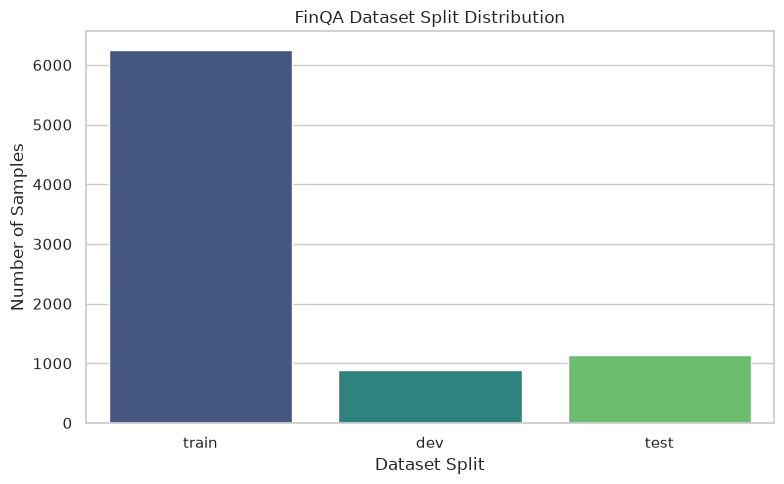

In [4]:
split_summary = pd.DataFrame(
    [{"Split": name, "Samples": len(data)} for name, data in split_data.items()]
)
display(split_summary)

plt.figure(figsize=(8, 5))
sns.barplot(data=split_summary, x="Split", y="Samples", hue="Split", legend=False, palette="viridis")
plt.title("FinQA Dataset Split Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


## 3. Inspect a Raw Record

In [5]:
sample = split_data["train"][0]

print("Top-level fields:")
for key, value in sample.items():
    print(f"  {key:25} -> {type(value).__name__}")

print()
print("QA fields:")
for key, value in (sample.get("qa") or {}).items():
    print(f"  {key:25} -> {type(value).__name__}")


Top-level fields:
  pre_text                  -> list
  post_text                 -> list
  filename                  -> str
  table_ori                 -> list
  table                     -> list
  qa                        -> dict
  id                        -> str
  table_retrieved           -> list
  text_retrieved            -> list
  table_retrieved_all       -> list
  text_retrieved_all        -> list

QA fields:
  question                  -> str
  answer                    -> str
  explanation               -> str
  ann_table_rows            -> list
  ann_text_rows             -> list
  steps                     -> list
  program                   -> str
  gold_inds                 -> dict
  exe_ans                   -> float
  tfidftopn                 -> dict
  program_re                -> str
  model_input               -> list


In [6]:
print(json.dumps(sample.get("qa", sample), indent=2, ensure_ascii=False)[:1500])


{
  "question": "what is the the interest expense in 2009?",
  "answer": "380",
  "explanation": "",
  "ann_table_rows": [],
  "ann_text_rows": [
    1
  ],
  "steps": [
    {
      "op": "divide1-1",
      "arg1": "100",
      "arg2": "100",
      "res": "1%"
    },
    {
      "op": "divide1-2",
      "arg1": "3.8",
      "arg2": "#0",
      "res": "380"
    }
  ],
  "program": "divide(100, 100), divide(3.8, #0)",
  "gold_inds": {
    "text_1": "if libor changes by 100 basis points , our annual interest expense would change by $ 3.8 million ."
  },
  "exe_ans": 3.8,
  "tfidftopn": {
    "text_14": "dollar , would have on the fair value of our forward exchange contracts as of october 31 , 2009 and november 1 , 2008: .",
    "text_0": "interest rate to a variable interest rate based on the three-month libor plus 2.05% ( 2.05 % ) ( 2.34% ( 2.34 % ) as of october 31 , 2009 ) ."
  },
  "program_re": "divide(3.8, divide(100, 100))",
  "model_input": [
    [
      "text_0",
      "interest 

## 4. Convert FinQA to a DataFrame

In [7]:
def flatten_finqa(data, split_name):
    def pick(qa, item, key):
        value = qa.get(key)
        return item.get(key) if value is None else value

    rows = []
    for item in data:
        qa = item.get("qa") or {}
        rows.append({
            "id": pick(qa, item, "id"),
            "split": split_name,
            "question": pick(qa, item, "question"),
            "answer": pick(qa, item, "answer"),
            "program": pick(qa, item, "program"),
            "gold_inds": qa.get("gold_inds") or item.get("gold_evidence"),
            "pre_text": item.get("pre_text"),
            "post_text": item.get("post_text"),
            "table": item.get("table"),
        })
    return pd.DataFrame(rows)

finqa_df = pd.concat(
    [flatten_finqa(data, name) for name, data in split_data.items()],
    ignore_index=True,
)

print("Combined shape:", finqa_df.shape)
display(finqa_df.head(3))


Combined shape: (8281, 9)


,id,split,question,answer,program,gold_inds,pre_text,post_text,table
0,ADI/2009/page_49.pdf-1,train,what is the the interest expense in 2009?,380,"divide(100, 100), divide(3.8, #0)","{'text_1': 'if libor changes by 100 basis points , our annual interest expense would change by $ 3.8 million .'}","[interest rate to a variable interest rate based on the three-month libor plus 2.05% ( 2.05 % ) ( 2.34% ( 2.34 % ) as of october 31 , 2009 ) ., if libor changes by 100 basis points , our annual in...","[fair value of forward exchange contracts after a 10% ( 10 % ) unfavorable movement in foreign currency exchange rates asset ( liability ) ., ., ., ., ., ., ., ., ., $ 20132 $ ( 9457 ) fair value ...","[[, october 31 2009, november 1 2008], [fair value of forward exchange contracts asset ( liability ), $ 6427, $ -23158 ( 23158 )], [fair value of forward exchange contracts after a 10% ( 10 % ) un..."
1,ABMD/2012/page_75.pdf-1,train,"during the 2012 year , did the equity awards in which the prescribed performance milestones were achieved exceed the equity award compensation expense for equity granted during the year?",,"multiply(607, 18.13), multiply(#0, const_1000), multiply(3.3, const_1000000), greater(#1, #2)","{'table_2': 'the granted of number of shares ( in thousands ) is 607 ; the granted of weighted average grant date fair value ( per share ) is 18.13 ;', 'text_15': 'during the year ended march 31 ,...","[abiomed , inc ., and subsidiaries notes to consolidated financial statements 2014 ( continued ) note 8 ., stock award plans and stock-based compensation ( continued ) restricted stock and restric...","[the remaining unrecognized compensation expense for outstanding restricted stock and restricted stock units , including performance-based awards , as of march 31 , 2012 was $ 7.1 million and the ...","[[, number of shares ( in thousands ), weighted average grant date fair value ( per share )], [restricted stock and restricted stock units at beginning of year, 407, $ 9.84], [granted, 607, 18.13]..."
2,AAL/2018/page_13.pdf-2,train,what was the total operating expenses in 2018 in millions,41932,"divide(9896, 23.6%)",{'table_1': 'year the 2018 of gallons is 4447 ; the 2018 of average priceper gallon is $ 2.23 ; the 2018 of aircraft fuelexpense is $ 9896 ; the 2018 of percent of totaloperating expenses is 23.6%...,"[the following table shows annual aircraft fuel consumption and costs , including taxes , for our mainline and regional operations for 2018 , 2017 and 2016 ( gallons and aircraft fuel expense in m...","[as of december 31 , 2018 , we did not have any fuel hedging contracts outstanding to hedge our fuel consumption ., as such , and assuming we do not enter into any future transactions to hedge our...","[[year, gallons, average priceper gallon, aircraft fuelexpense, percent of totaloperating expenses], [2018, 4447, $ 2.23, $ 9896, 23.6% ( 23.6 % )], [2017, 4352, 1.73, 7510, 19.6% ( 19.6 % )], [20..."


In [8]:
print("Columns:", finqa_df.columns.tolist())
print()
display(finqa_df.dtypes.to_frame("dtype"))


Columns: ['id', 'split', 'question', 'answer', 'program', 'gold_inds', 'pre_text', 'post_text', 'table']



,dtype
id,str
split,str
question,str
answer,str
program,str
gold_inds,object
pre_text,object
post_text,object
table,object


## 5. Duplicate and Missing-Value Analysis

In [9]:
print("Duplicate IDs:", int(finqa_df["id"].duplicated().sum()))
print("Duplicate questions:", int(finqa_df["question"].duplicated().sum()))

duplicated_questions = finqa_df[finqa_df["question"].duplicated(keep=False)]
if len(duplicated_questions):
    display(duplicated_questions[["id", "split", "question"]].head(10))


Duplicate IDs: 0
Duplicate questions: 163


,id,split,question
13,ETR/2008/page_376.pdf-2,train,what is the percent change in net revenue between 2007 and 2008?
25,HII/2018/page_64.pdf-4,train,what portion of total backlog is related to ingalls segment?
28,TSCO/2017/page_68.pdf-3,train,what was the total amount lost from the bond authorization to the withdrawn?
47,JPM/2018/page_73.pdf-5,train,did jpmorgan chase outperform the kbw bank index?
70,DISCA/2013/page_60.pdf-1,train,"what was the percentage cumulative total shareholder return on disca for the five year period ended december 21 , 2013?"
74,ETR/2004/page_216.pdf-4,train,what is the percent change in receivables from or ( payables to ) the money pool from 2001 to 2002?
143,DVN/2004/page_50.pdf-2,train,"how much of the oil production is estimated to be produced from unproved reserves at dec 31 , 2004 , in mmbbls?"
149,HUM/2015/page_46.pdf-2,train,what is the highest return for the first year of the investment?
185,REGN/2010/page_72.pdf-3,train,what was the percentage change in research and development costs related to arcalyst ae from 2008 to 2009?
220,HOLX/2006/page_102.pdf-1,train,what percentage of the estimated purchase price is goodwill?


In [10]:
missing_df = pd.DataFrame({
    "Missing Values": finqa_df.isnull().sum(),
    "Missing Percentage": (finqa_df.isnull().mean() * 100).round(2),
})
display(missing_df.sort_values("Missing Percentage", ascending=False))


,Missing Values,Missing Percentage
id,0,0.0
split,0,0.0
question,0,0.0
answer,0,0.0
program,0,0.0
gold_inds,0,0.0
pre_text,0,0.0
post_text,0,0.0
table,0,0.0


In [11]:
plot_missing = missing_df[missing_df["Missing Values"] > 0].sort_values("Missing Percentage", ascending=False)

if len(plot_missing) == 0:
    print("No missing values detected in the flattened fields.")
else:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=plot_missing["Missing Percentage"], y=plot_missing.index, hue=plot_missing.index, legend=False, palette="Reds_r")
    plt.title("Missing Values in FinQA")
    plt.xlabel("Missing Percentage (%)")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


No missing values detected in the flattened fields.


## 6. Text-Length Analysis

In [12]:
def to_text(value):
    if isinstance(value, list):
        return " ".join(map(str, value))
    return "" if value is None else str(value)

def word_count(value):
    return len(to_text(value).split())

finqa_df["question_length_words"] = finqa_df["question"].apply(word_count)
finqa_df["pre_text_words"] = finqa_df["pre_text"].apply(word_count)
finqa_df["post_text_words"] = finqa_df["post_text"].apply(word_count)
finqa_df["answer_length_words"] = finqa_df["answer"].apply(word_count)
finqa_df["program_length_tokens"] = finqa_df["program"].apply(lambda x: len(str(x).split()) if x is not None else 0)

length_cols = [
    "question_length_words",
    "pre_text_words",
    "post_text_words",
    "answer_length_words",
    "program_length_tokens",
]

display(finqa_df[length_cols].describe().round(2))


,question_length_words,pre_text_words,post_text_words,answer_length_words,program_length_tokens
count,8281.00,8281.00,8281.00,8281.00,8281.00
mean,16.63,301.14,326.94,1.07,3.14
std,5.73,237.98,258.18,1.34,1.63
min,5.00,1.00,1.00,0.00,2.00
25%,13.00,96.00,111.00,1.00,2.00
50%,15.00,248.00,291.00,1.00,2.00
75%,19.00,473.00,516.00,1.00,4.00
max,62.00,1309.00,1489.00,69.00,12.00


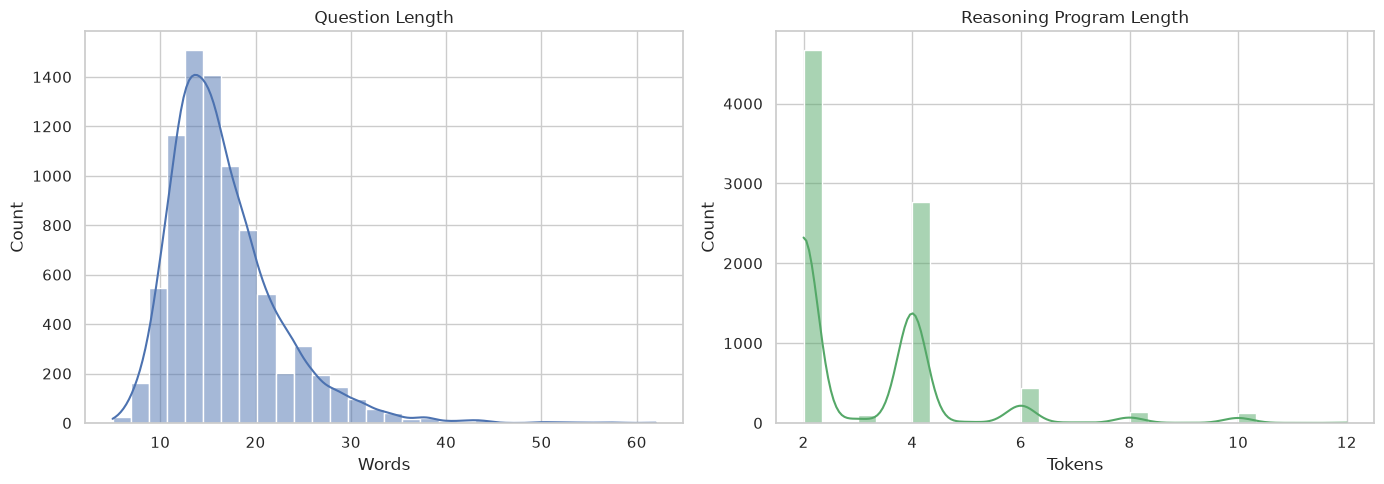

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(finqa_df["question_length_words"], bins=30, kde=True, ax=axes[0], color="#4c72b0")
axes[0].set_title("Question Length")
axes[0].set_xlabel("Words")

sns.histplot(finqa_df["program_length_tokens"], bins=30, kde=True, ax=axes[1], color="#55a868")
axes[1].set_title("Reasoning Program Length")
axes[1].set_xlabel("Tokens")

plt.tight_layout()
plt.show()


## 7. Financial Table Analysis

In [14]:
def table_shape(table):
    if not isinstance(table, list) or len(table) == 0:
        return 0, 0
    valid_rows = [r for r in table if isinstance(r, list)]
    return len(table), max((len(r) for r in valid_rows), default=0)

shapes = finqa_df["table"].apply(table_shape)
finqa_df["table_rows"] = shapes.apply(lambda x: x[0])
finqa_df["table_columns"] = shapes.apply(lambda x: x[1])
finqa_df["table_cells"] = finqa_df["table_rows"] * finqa_df["table_columns"]

display(finqa_df[["table_rows", "table_columns", "table_cells"]].describe().round(2))


,table_rows,table_columns,table_cells
count,8281.00,8281.00,8281.00
mean,6.36,3.86,23.67
std,2.62,1.57,12.80
min,1.00,2.00,4.00
25%,4.00,3.00,15.00
50%,6.00,4.00,20.00
75%,8.00,4.00,28.00
max,20.00,14.00,165.00


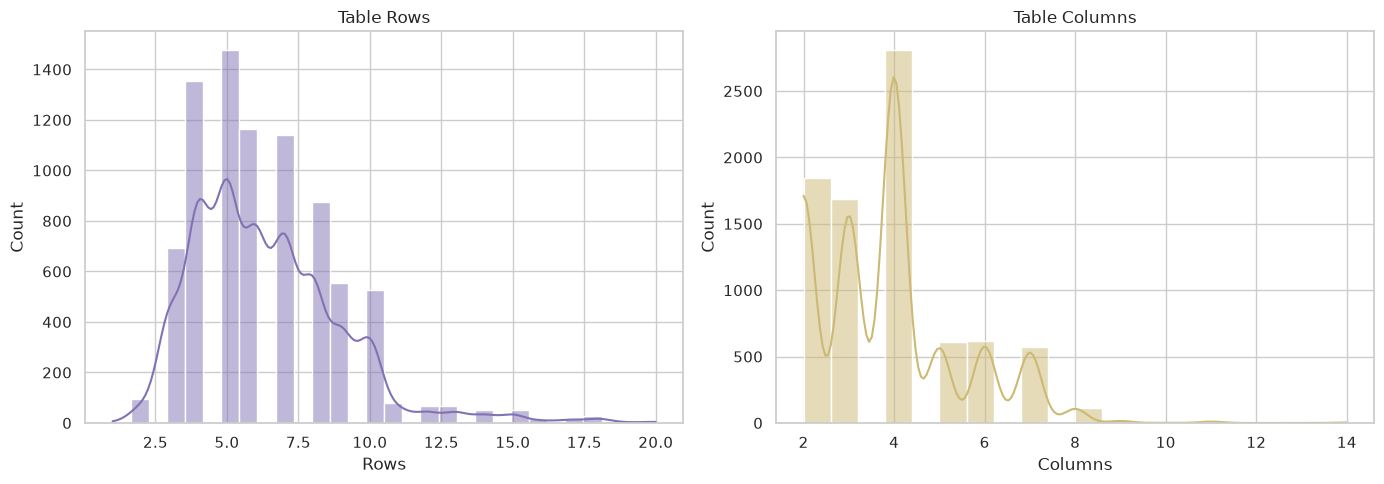

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(finqa_df["table_rows"], bins=30, kde=True, ax=axes[0], color="#8172b3")
axes[0].set_title("Table Rows")
axes[0].set_xlabel("Rows")

sns.histplot(finqa_df["table_columns"], bins=20, kde=True, ax=axes[1], color="#ccb974")
axes[1].set_title("Table Columns")
axes[1].set_xlabel("Columns")

plt.tight_layout()
plt.show()


## 8. Answer-Type Analysis

,Answer Type,Count,Share (%)
0,Percentage,4652,56.2
1,Numeric,3403,41.1
2,Text,152,1.8
3,Empty/None,74,0.9


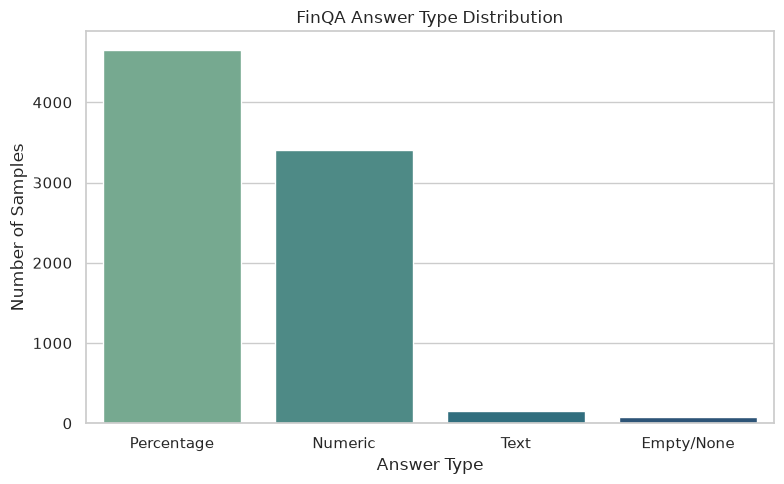

In [16]:
def classify_answer(answer):
    text = str(answer).strip()
    if text == "" or text.lower() == "none":
        return "Empty/None"
    if "%" in text:
        return "Percentage"
    if re.search(r"\d", text):
        return "Numeric"
    return "Text"

finqa_df["answer_type_eda"] = finqa_df["answer"].apply(classify_answer)

answer_type_counts = (
    finqa_df["answer_type_eda"]
    .value_counts()
    .rename_axis("Answer Type")
    .reset_index(name="Count")
)

answer_type_counts["Share (%)"] = (answer_type_counts["Count"] / answer_type_counts["Count"].sum() * 100).round(1)
display(answer_type_counts)

plt.figure(figsize=(8, 5))
sns.barplot(data=answer_type_counts, x="Answer Type", y="Count", hue="Answer Type", legend=False, palette="crest")
plt.title("FinQA Answer Type Distribution")
plt.xlabel("Answer Type")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


## 9. Reasoning Program / Operation Analysis

The gold `program` field encodes how the answer is computed from the evidence,
e.g. `divide(3.8, divide(100, 100))`. Counting the operations shows what kinds of
arithmetic a trustworthy SLM must learn to perform.

In [17]:
operation_counter = Counter()

for program in finqa_df["program"].dropna():
    for op in re.findall(r"([A-Za-z_][A-Za-z0-9_]*)\(", str(program)):
        operation_counter[op] += 1

operation_df = (
    pd.DataFrame(operation_counter.items(), columns=["Operation", "Frequency"])
    .sort_values("Frequency", ascending=False)
    .reset_index(drop=True)
)
operation_df["Share (%)"] = (operation_df["Frequency"] / operation_df["Frequency"].sum() * 100).round(1)

display(operation_df.head(15))


,Operation,Frequency,Share (%)
0,divide,5901,46.3
1,subtract,3676,28.9
2,add,1952,15.3
3,multiply,759,6.0
4,greater,154,1.2
5,table_average,129,1.0
6,table_max,66,0.5
7,table_sum,50,0.4
8,table_min,36,0.3
9,exp,9,0.1


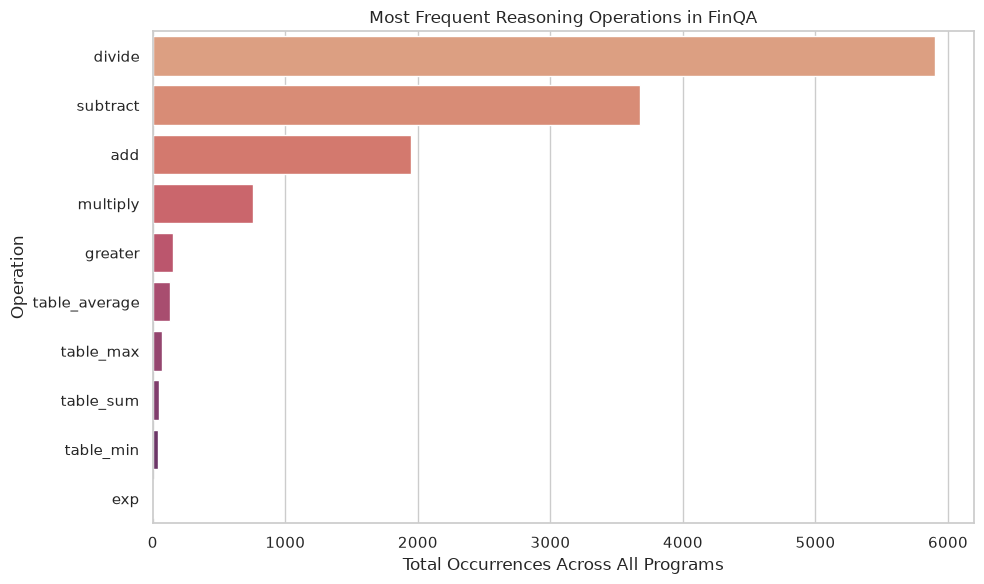

In [18]:
plt.figure(figsize=(10, 6))
top_operations = operation_df.head(15)
sns.barplot(data=top_operations, x="Frequency", y="Operation", hue="Operation", legend=False, palette="flare")
plt.title("Most Frequent Reasoning Operations in FinQA")
plt.xlabel("Total Occurrences Across All Programs")
plt.ylabel("Operation")
plt.tight_layout()
plt.show()


## 10. Evidence / Gold-Information Analysis

In [19]:
print("Example gold_inds:")
print(json.dumps(finqa_df["gold_inds"].iloc[0], indent=2, ensure_ascii=False)[:800])

def evidence_count(value):
    if isinstance(value, (dict, list)):
        return len(value)
    if value is None:
        return 0
    return 1

finqa_df["evidence_count_eda"] = finqa_df["gold_inds"].apply(evidence_count)

print()
display(finqa_df["evidence_count_eda"].describe().round(2).to_frame("Evidence Count"))


Example gold_inds:
{
  "text_1": "if libor changes by 100 basis points , our annual interest expense would change by $ 3.8 million ."
}



,Evidence Count
count,8281.00
mean,1.70
std,0.85
min,1.00
25%,1.00
50%,2.00
75%,2.00
max,9.00


## 11. Train / Dev / Test Comparison

In [20]:
split_stats = finqa_df.groupby("split").agg(
    samples=("id", "count"),
    avg_question_words=("question_length_words", "mean"),
    avg_context_words=("pre_text_words", "mean"),
    avg_answer_words=("answer_length_words", "mean"),
    avg_program_length=("program_length_tokens", "mean"),
    avg_table_rows=("table_rows", "mean"),
    avg_table_columns=("table_columns", "mean"),
    avg_evidence_count=("evidence_count_eda", "mean"),
).round(2)

display(split_stats)


,samples,avg_question_words,avg_context_words,avg_answer_words,avg_program_length,avg_table_rows,avg_table_columns,avg_evidence_count
split,,,,,,,,
dev,883,16.41,284.11,1.03,3.16,6.27,3.94,1.71
test,1147,16.72,309.62,1.06,3.15,6.55,3.92,1.66
train,6251,16.65,301.99,1.08,3.13,6.34,3.84,1.71


## 12. Random Examples

In [21]:
display(
    finqa_df[["split", "question", "answer", "program"]]
    .sample(min(5, len(finqa_df)), random_state=42)
)


,split,question,answer,program
2917,train,"for the awcc commercial paper program that is backed by the revolving credit facility , what was the change in billions of the maximum aggregate outstanding amount from march 2018 , to december 2018?",0.5,"subtract(2.10, 1.60)"
3317,train,"as of december 2012 and 2011 in millions , what is the minimum total capital?",77143,"table_min(total capital, none)"
5296,train,"at december 31 , 2014 what was the structured notes fva balance in billions?",-0.25,"divide(1152, const_1000), subtract(#0, 1.4)"
7274,test,what is the expected percentage change in aggregate principal payments of long-term debt from 2004 to 2005?,48.5%,"subtract(109435, 73684), divide(#0, 73684)"
7020,dev,"considering the second quarter of 2017 , what is the average sale price per share of the company 2019s common stock?",25.20,"add(28.65, 21.76), divide(#0, const_2)"


## 13. Complete Example Viewer

In [22]:
example = finqa_df.iloc[0]

for label, key in [("SPLIT", "split"), ("QUESTION", "question"), ("ANSWER", "answer"), ("REASONING PROGRAM", "program")]:
    print("=" * 90)
    print(label)
    print("=" * 90)
    print(example[key])
    print()

print("=" * 90)
print("GOLD EVIDENCE")
print("=" * 90)
print(json.dumps(example["gold_inds"], indent=2, ensure_ascii=False))
print()

print("=" * 90)
print("TABLE")
print("=" * 90)
for row in example["table"]:
    print(row)


SPLIT
train

QUESTION
what is the the interest expense in 2009?

ANSWER
380

REASONING PROGRAM
divide(100, 100), divide(3.8, #0)

GOLD EVIDENCE
{
  "text_1": "if libor changes by 100 basis points , our annual interest expense would change by $ 3.8 million ."
}

TABLE
['', 'october 31 2009', 'november 1 2008']
['fair value of forward exchange contracts asset ( liability )', '$ 6427', '$ -23158 ( 23158 )']
['fair value of forward exchange contracts after a 10% ( 10 % ) unfavorable movement in foreign currency exchange rates asset ( liability )', '$ 20132', '$ -9457 ( 9457 )']
['fair value of forward exchange contracts after a 10% ( 10 % ) favorable movement in foreign currency exchange rates liability', '$ -6781 ( 6781 )', '$ -38294 ( 38294 )']


## 14. TrustFin-SLM Training Sample (`finqa_trustfin_sample.csv`)

This CSV is a small curated sample converted from FinQA into **instruction-tuning
format**: each row pairs a financial context + question (`user_prompt`) with a
grounded, step-by-step answer (`assistant_response`) that cites evidence and shows
the reasoning program. This is the format used to fine-tune the trustworthy SLM.

In [23]:
trustfin_df = pd.read_csv(TRUSTFIN_CSV)

print("Shape:", trustfin_df.shape)
print("Duplicate IDs:", int(trustfin_df["id"].duplicated().sum()))
print()
print("Columns:", trustfin_df.columns.tolist())
display(trustfin_df.head(3))


Shape: (8, 9)
Duplicate IDs: 0

Columns: ['id', 'category', 'context', 'question', 'answer', 'explanation', 'program', 'user_prompt', 'assistant_response']


,id,category,context,question,answer,explanation,program,user_prompt,assistant_response
0,ADI/2009/page_49.pdf-1,financial_numerical_reasoning,"If LIBOR changes by 100 basis points, our annual interest expense would change by $3.8 million.",What is the interest expense in 2009?,380,"The dataset's reasoning divides 100 by 100 to normalize the basis-point percentage, then divides 3.8 by that result.","divide(3.8, divide(100, 100))","Financial context:\nIf LIBOR changes by 100 basis points, our annual interest expense would change by $3.8 million.\n\nQuestion:\nWhat is the interest expense in 2009?","Evidence: The annual interest expense changes by $3.8 million for a 100-basis-point change in LIBOR.\nCalculation: divide(3.8, divide(100, 100)) = 380.\nAnswer: 380."
1,ABMD/2012/page_75.pdf-1,financial_comparison,The table reports 607 thousand shares granted at a weighted average grant-date fair value of $18.13. The company recorded $3.3 million in stock-based compensation expense for the relevant equity a...,"During the 2012 year, did the equity awards in which the prescribed performance milestones were achieved exceed the equity award compensation expense for equity granted during the year?",yes,"607 × 18.13 × 1,000 = 11,005,000, which exceeds $3.3 million.","greater(multiply(multiply(607, 18.13), const_1000), multiply(3.3, const_1000000))",Financial context:\nThe table reports 607 thousand shares granted at a weighted average grant-date fair value of $18.13. The company recorded $3.3 million in stock-based compensation expense for t...,"Evidence: 607 thousand shares × $18.13 fair value = $11.005 million, compared with $3.3 million compensation expense.\nCalculation: $11.005M > $3.3M.\nAnswer: Yes."
2,AAL/2018/page_13.pdf-2,financial_ratio,"In 2018, aircraft fuel expense was $9,896 million and represented 23.6% of total operating expenses.",What were the total operating expenses in 2018 in millions?,41932,Total operating expenses are obtained by dividing fuel expense by the percentage of operating expenses.,"divide(9896, 23.6%)","Financial context:\nIn 2018, aircraft fuel expense was $9,896 million and represented 23.6% of total operating expenses.\n\nQuestion:\nWhat were the total operating expenses in 2018 in millions?","Evidence: Fuel expense = $9,896M and equals 23.6% of operating expenses.\nCalculation: 9,896 / 0.236 ≈ 41,932M.\nAnswer: Approximately $41,932 million."


,Category,Count
0,financial_ratio,2
1,financial_numerical_reasoning,1
2,financial_comparison,1
3,growth_rate,1
4,financial_calculation,1
5,percentage_change,1
6,financial_difference,1


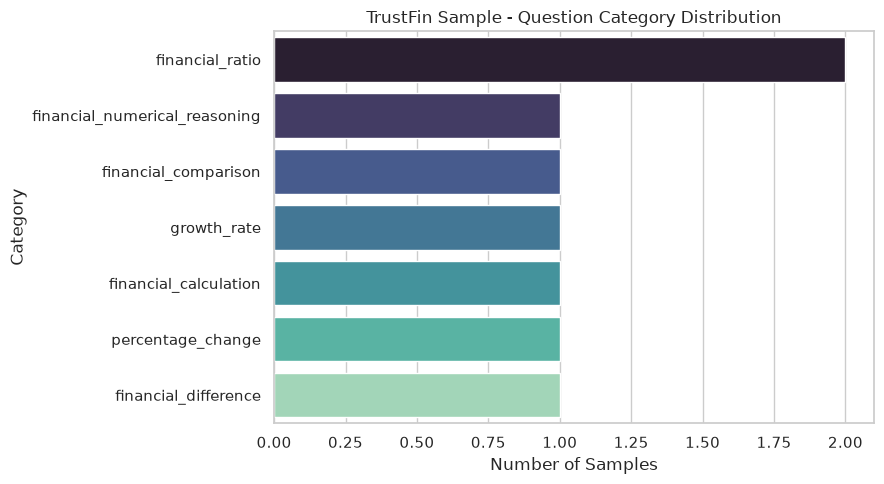

In [24]:
category_counts = (
    trustfin_df["category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Count")
)

display(category_counts)

plt.figure(figsize=(9, 5))
sns.barplot(data=category_counts, x="Count", y="Category", hue="Category", legend=False, palette="mako")
plt.title("TrustFin Sample - Question Category Distribution")
plt.xlabel("Number of Samples")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


In [25]:
trustfin_df["prompt_words"] = trustfin_df["user_prompt"].str.split().str.len()
trustfin_df["response_words"] = trustfin_df["assistant_response"].str.split().str.len()

display(trustfin_df[["prompt_words", "response_words"]].describe().round(1))


,prompt_words,response_words
count,8.0,8.0
mean,31.4,23.1
std,12.6,2.4
min,22.0,21.0
25%,24.8,21.0
50%,27.0,23.0
75%,32.2,24.0
max,61.0,28.0


In [26]:
consistency = trustfin_df.merge(
    finqa_df[["id", "program", "answer"]],
    on="id",
    how="left",
    suffixes=("", "_finqa"),
)

matched = consistency["program_finqa"].notna().sum()
programs_match = (consistency["program"].astype(str) == consistency["program_finqa"].astype(str)).sum()
answers_match = (consistency["answer"].astype(str) == consistency["answer_finqa"].astype(str)).sum()

print(f"Rows matched back to FinQA: {matched} / {len(consistency)}")
print(f"Programs identical to FinQA gold: {programs_match} / {len(consistency)}")
print(f"Answers identical to FinQA gold:  {answers_match} / {len(consistency)}")


Rows matched back to FinQA: 8 / 8
Programs identical to FinQA gold: 3 / 8
Answers identical to FinQA gold:  7 / 8


In [27]:
row = trustfin_df.iloc[0]

for field in ["id", "category", "question", "answer", "program"]:
    print(f"{field.upper()}: {row[field]}")

print()
print("USER PROMPT:")
print(row["user_prompt"])
print()
print("ASSISTANT RESPONSE:")
print(row["assistant_response"])


ID: ADI/2009/page_49.pdf-1
CATEGORY: financial_numerical_reasoning
QUESTION: What is the interest expense in 2009?
ANSWER: 380
PROGRAM: divide(3.8, divide(100, 100))

USER PROMPT:
Financial context:
If LIBOR changes by 100 basis points, our annual interest expense would change by $3.8 million.

Question:
What is the interest expense in 2009?

ASSISTANT RESPONSE:
Evidence: The annual interest expense changes by $3.8 million for a 100-basis-point change in LIBOR.
Calculation: divide(3.8, divide(100, 100)) = 380.
Answer: 380.


So from the above we can see that what is the model/assitants reponse to the user prompt is the answer to the question with step-by-step reasoning and evidence citation. The model is trained to provide accurate and trustworthy responses based on the financial context provided in the prompt.. and the type of teh input the user can give like the numerical or the textual info like what is the last year revenur and the other is theat what is the percentage of 100k in the total revenue of 1 million. The model is expected to handle both types of inputs and provide accurate calculations or information based on the financial data provided.here the duplication removal is been done and after this the preprocessing the data is done to make it ready for training the model. The model is expected to learn from this curated dataset and generalize well to unseen financial questions and contexts.with this the synathetic data is to be used also with this with the use of unsloths recipe in whcih the current dataset and the synthetic data is combined to create a more diverse and comprehensive training set. This approach aims to enhance the model's ability to handle a wider range of financial queries and improve its overall performance in real-world scenarios.